In [2]:
%matplotlib inline

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("data.csv", encoding = 'unicode_escape') 
# encoding is used since the data has UTF-8 characters
print("The shape of the database:", df.shape)
display(df.head())

The shape of the database: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
# Cleaning the database to have better results.
df = df.dropna(subset = ["CustomerID"]).copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("The cleaner shape value:", df.shape) # 9 rows because I added Revenue column. 
print("Number of unique customers:", df["CustomerID"].nunique())

The cleaner shape value: (397884, 9)
Number of unique customers: 4338


In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days = 1)

rfm = df.groupby("CustomerID").agg(
    Recency = ("InvoiceDate", lambda dates : (reference_date - dates.max().normalize()).days),
    Frequency = ("InvoiceNo", "nunique"), Monetary = ("Revenue", "sum")).reset_index()

print("Customer shape:", rfm.shape)
display(rfm.head())

# New rows I will use later in this code
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Customer shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.75,5.00,1661.74
max,374.00,209.00,280206.02


In [6]:
features = ["Recency", "Frequency", "Monetary"]
X_log = np.log1p(rfm[features])
X = StandardScaler().fit_transform(X_log)

In [7]:
results = []
for k in range(2, 9):
    model = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    labels = model.fit_predict(X)
    results.append({"k" : k, "Inertia" : model.inertia_, "Silhouette" : silhouette_score(X, labels)})
    
scores = pd.DataFrame(results)
display(scores.round(3))

,k,Inertia,Silhouette
0,2,6474.146,0.433
1,3,4856.586,0.336
2,4,3924.460,0.336
3,5,3268.212,0.318
4,6,2840.151,0.316
5,7,2533.024,0.310
6,8,2325.523,0.302


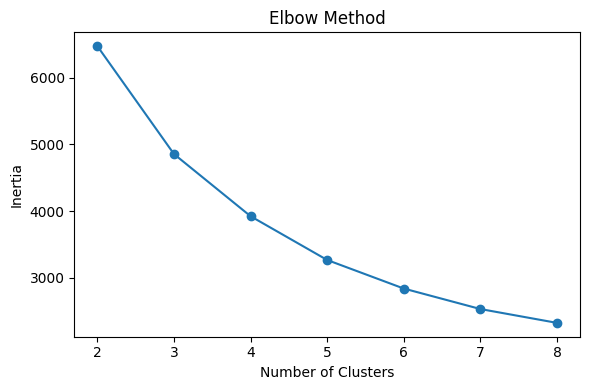

In [9]:
fig, ax = plt.subplots(figsize = (6, 4))
ax.plot(scores["k"], scores["Inertia"], marker = "o")
ax.set(title = "Elbow Method", xlabel = "Number of Clusters", ylabel = "Inertia")
plt.tight_layout()
plt.savefig("elbow_method.png")
plt.show()

In [10]:
kmeans = KMeans(n_clusters = 4, random_state = 42, n_init = 10)
rfm["Cluster"] = kmeans.fit_predict(X)

summary_clusters = rfm.groupby("Cluster").agg(
    Customers = ("CustomerID", "count"),
    Avg_Recency = ("Recency", "mean"),
    Avg_Frequency = ("Frequency", "mean"),
    Avg_Monetary = ("Monetary", "mean"),
    Median_Recency = ("Recency", "median"),
    Median_Frequency = ("Frequency", "median"),
    Median_Monetary = ("Monetary", "median"),
).round(2)

display(summary_clusters)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary
Cluster,,,,,,,
0,877,20.56,2.05,527.17,19.0,2.0,450.84
1,1579,187.68,1.33,352.13,183.0,1.0,300.42
2,720,12.51,13.66,8037.21,9.0,10.0,3726.08
3,1162,69.11,4.13,1812.63,54.0,4.0,1353.74


In [11]:
centers = kmeans.cluster_centers_
distances = np.linalg.norm(X - centers[rfm["Cluster"].to_numpy()], axis = 1)
rfm["DistanceToCenter"] = distances

representatives = (rfm.sort_values("DistanceToCenter").groupby("Cluster").head(2).
                   sort_values(["Cluster", "DistanceToCenter"]))

display(representatives[["Cluster", "CustomerID", "Recency", "Frequency", "Monetary", "DistanceToCenter"]].round(2))

,Cluster,CustomerID,Recency,Frequency,Monetary,DistanceToCenter
2081,0,15186.0,15,2,411.41,0.07
87,0,12452.0,17,2,430.57,0.08
3741,1,17464.0,159,1,289.96,0.19
1036,1,13745.0,163,1,300.04,0.20
2787,2,16145.0,9,11,3799.49,0.10
2368,2,15570.0,8,12,4165.52,0.13
1537,3,14443.0,54,4,1420.20,0.05
2966,3,16389.0,54,4,1382.07,0.05


In [12]:
print("Missing values:")
display(rfm[features].isna().sum())

print("Cluster size:")
display(rfm["Cluster"].value_counts().sort_index())

print("RFM ranges:")
display(rfm[features].agg(["min", "max"]).T)

rfm.to_csv("customer_rfm_clusters.csv", index = False)
summary_clusters.to_csv("summary_clusters.csv")
representatives.to_csv("representatives_customers.csv", index = False)
scores.to_csv("k_selection_scores.csv", index = False)

Missing values:


Recency      0
Frequency    0
Monetary     0
dtype: int64

Cluster size:


Cluster
0     877
1    1579
2     720
3    1162
Name: count, dtype: int64

RFM ranges:


,min,max
Recency,1.00,374.00
Frequency,1.00,209.00
Monetary,3.75,280206.02
